In [ ]:
#đọc dữ liệu từ file
import pandas as pd

df = pd.read_csv("../data/loan.csv", nrows=10000)

In [ ]:
print("---SỐ DÒNG, CỘT CỦA BẢNG")
df.shape

In [ ]:
print("---DS CÁC CỘT")
df.columns

In [ ]:
print("---KIỂU DỮ LIỆU CÁC CỘT")
df.info()

In [ ]:
print("---10 DÒNG ĐẦU + 10 DÒNG CUỐI CỦA BẢNG")
df.head(10)
df.tail(10)

In [ ]:
#phân ra catogrical columns
cat_cols = df.select_dtypes(
    include=['string']).columns.to_list()
print(cat_cols)
len(cat_cols)

In [ ]:
#phân ra numerical columns
num_cols = df.select_dtypes(
    include=['float64','int64']).columns.to_list()
print(num_cols)
len(num_cols)

In [ ]:
#kiểm tra missing values (missing values analysis)
missing = df.isnull().sum().sort_values(ascending=False)
#isnull() nó sẽ tạo 1 bảng nơi các ô trống là True

missing_pct = df.isnull().mean()*100
#từ đó True được hiểu là 1 trong py nên chỉ cần dùng mean để lấy True/tổng dòng
missing_pct[~missing_pct.isin([0,100])]
#~ được hiểu là phủ định
#missing_pct[missing_pct.between(0,100, inclusive='neither')] là cách ghi khác


C:\Users\bphuy\AppData\Local\Temp\ipykernel_25308\23019356.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing_pct.index, y=missing_pct.values,palette='viridis')


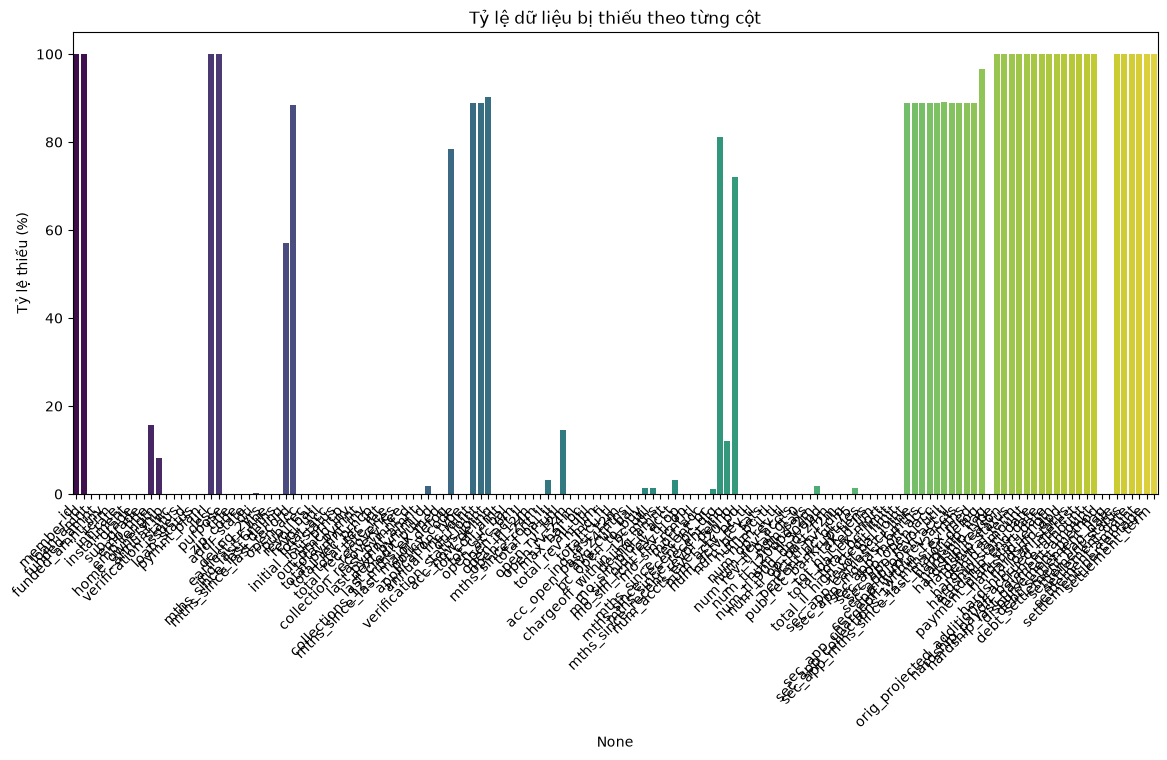

In [30]:
#tạo đồ thị dữ liệu để tiện quan sát
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(14,6))
sns.barplot(x=missing_pct.index, y=missing_pct.values,palette='viridis')

plt.ylabel('Tỷ lệ thiếu (%)')
plt.title('Tỷ lệ dữ liệu bị thiếu theo từng cột')
plt.xticks(rotation=45, ha='right')
plt.show()

In [ ]:
#xóa các cột missing values >50%
cols_to_drop = missing_pct[missing_pct>50].index
df_cleaned = df.drop(columns=cols_to_drop)
print("---ĐÃ XÓA CÁC CỘT TRỐNG")